# Statistical Arbitrage in Cryptocurrencies

**Goal (from the project brief):** research profitable momentum and/or reversal strategies in crypto, net of realistic execution costs, combine them, and evaluate the result.

**Summary of findings**

| | net Sharpe (20 bps) |
|---|---|
| Final strategy, in-sample (Binance.US, Mar-2021 → Dec-2025) | **1.43** (max drawdown −13%) |
| Final strategy, Binance global, in-sample period | 1.73 |
| Final strategy, **out-of-sample** (Binance global, Jan-2025 → Oct-2026) | **1.17** (2025: 1.97; 2026 Jan–Oct: −0.05) |

The final strategy is a risk-parity combination of four nearly uncorrelated strategies: cross-sectional momentum, time-series momentum, a fire-sale reversal, and betting-against-beta.

**Contents**
0. Setup and helper functions
1. Data
2. Momentum: time horizon
3. Transaction costs and execution
4. A better cross-sectional momentum signal
5. Momentum and activity (volume)
6. Time-series momentum
7. Reversal
8. Betting against beta
9. Weighting: combining the strategies
10. Performance evaluation
11. Out-of-sample test on Binance global data
12. Conclusions and limitations

## 0. Setup and helper functions

Conventions used everywhere:
- Data are **4-hour bars**; a year has 365 × 6 = 2190 bars (crypto trades every day).
- `w` = target weights (coins in columns). `held = w.shift(lag)` is the position during each bar, so a signal computed at the close of bar *t* is earliest held during bar *t+1* (no look-ahead).
- **Turnover** = Σ|change in held weights|. **Costs**: 20 bps per unit traded for market orders (7 bps commission + 13 bps slippage), 7 bps for limit orders.
- **Break-even cost** = average gross return / average turnover: the largest cost per unit traded a strategy can pay and still break even.

In [2]:
import itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cvxpy as cvx
from sklearn.covariance import LedoitWolf

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)

BARS_PER_YEAR = 365*6
COST = 0.0020          # market orders: 7 bps commission + 13 bps slippage
COST_LIMIT = 0.0007    # limit orders: commission only

In [3]:
# ---------- statistics ----------
def sharpe(x):
    return x.mean()/x.std()*np.sqrt(BARS_PER_YEAR)

def max_drawdown(x):                       # on the cumulative (summed) return
    cum = x.cumsum()
    return (cum - cum.cummax()).min()

def perf(x, mkt):
    # Sharpe, return, vol, drawdown and beta to the market for one return series
    m = mkt.loc[x.index]
    return pd.Series({'Sharpe': sharpe(x), 'annual return': x.mean()*BARS_PER_YEAR,
                      'annual vol': x.std()*np.sqrt(BARS_PER_YEAR), 'max drawdown': max_drawdown(x),
                      'beta': x.cov(m)/m.var()})

# ---------- portfolio construction ----------
def norm(s):
    # demean across coins (dollar neutral) and scale so that sum|w| = 1
    s = s.sub(s.mean(axis=1), axis=0)
    return s.div(s.abs().sum(axis=1), axis=0)

def equal_weight(r):
    listed = r.notna()
    return listed.astype(float).div(listed.sum(axis=1), axis=0)

def hold_at(w, mask):
    # rebalance only where mask is True and hold in between.
    # fillna(0) first: a coin with no weight at a rebalance has no position (ffill would carry an old one)
    return w[mask].fillna(0).reindex(w.index).ffill()

# ---------- backtest ----------
def backtest(held, r):
    # held = position during each bar (already lagged) -> gross return and turnover per bar
    gross = (held*r).sum(axis=1)
    turnover = held.fillna(0).diff().abs().sum(axis=1)
    return gross, turnover

def cost_table(gross, to):
    # gross / to: DataFrames with one column per strategy
    return pd.DataFrame({
        'gross Sharpe':       sharpe(gross),
        'net Sharpe (20bps)': sharpe(gross - COST*to),
        'net Sharpe (7bps)':  sharpe(gross - COST_LIMIT*to),
        'avg turnover':       to.mean(),
        'breakeven (bps)':    gross.mean()/to.mean()*1e4,
    })

In [4]:
# ---------- signals ----------
def xs_momentum(r, h):
    # cross-sectional momentum: rank coins on their average return over the last h hours
    return norm(r.rolling(h//4, min_periods=1).mean().rank(axis=1))

def xs_momentum_mhva(r, horizons=(168, 336, 720)):
    # multi-horizon + volatility-adjusted momentum (Section 4)
    vol30 = r.rolling(180, min_periods=90).std()
    return norm(sum((r.rolling(h//4, min_periods=1).mean()/vol30).rank(axis=1) for h in horizons) / len(horizons))

def ts_market(r, lookbacks=(7, 14, 30, 60)):
    # time-series momentum on the equal-weight market: average of the signs of past L-day returns
    m = r.mean(axis=1)
    sig = pd.concat({L: np.sign(m.rolling(L*6, min_periods=L*6).sum()) for L in lookbacks},
                    axis=1).mean(axis=1, skipna=False)
    return equal_weight(r).mul(sig, axis=0), sig

def fire_sale(r, k=2.0, hold=6):
    # buy the market for `hold` bars after a 24h market drop below -k standard deviations
    m = r.mean(axis=1)
    z = m.rolling(6).sum() / (m.rolling(540, min_periods=270).std()*np.sqrt(6))
    s = pd.Series(np.where(z < -k, 1.0, np.nan), index=z.index).ffill(limit=hold-1).fillna(0)
    return equal_weight(r).mul(s, axis=0), s

def betting_against_beta(r):
    # long the low-beta half, short the high-beta half, each leg scaled by 1/(its average beta)
    m = r.mean(axis=1)
    beta = pd.DataFrame({c: r[c].rolling(540, min_periods=270).cov(m) / m.rolling(540, min_periods=270).var()
                         for c in r.columns})
    lo = beta.rank(axis=1, pct=True) <= 0.5
    hi = ~lo & beta.notna()
    w_lo = lo.astype(float).div(lo.sum(axis=1), axis=0).div(beta.where(lo).mean(axis=1), axis=0)
    w_hi = hi.astype(float).div(hi.sum(axis=1), axis=0).div(beta.where(hi).mean(axis=1), axis=0)
    w = w_lo - w_hi
    return w.div(w.abs().sum(axis=1), axis=0)

In [5]:
# ---------- rolling cvxpy optimization (Section 3.3) ----------
def tracking_error(w, ideal, sigma):
    # (w - ideal)' Sigma (w - ideal), written so that sigma enters as a PSD parameter
    P = cvx.Parameter(sigma.shape, value=sigma, PSD=True)
    return cvx.quad_form(w, P) - 2*ideal @ sigma @ w + ideal @ sigma @ ideal

def rolling_opt(ideal_w, r, tc_penalty, N=180):
    # Every day at 00:00: min tracking_error(w, ideal) + tc_penalty * COST * |w - w_prev|
    # s.t. sum(w) = 0, sum|w| <= 1, w = 0 for coins with no data.
    # w_prev is the position actually held (the previous solution), not the previous ideal.
    w = cvx.Variable(ideal_w.shape[1])
    w_prev = np.zeros(ideal_w.shape[1])
    out = {}
    for t in r.index[r.index.hour == 0]:
        ideal_raw = ideal_w.loc[t]
        ideal = ideal_raw.fillna(0).values
        sigma = LedoitWolf().fit(r.loc[:t].iloc[-N:].fillna(0).values).covariance_   # past 30 days only
        cons = [cvx.sum(w) == 0, cvx.norm1(w) <= 1]
        not_listed = ideal_raw.isna().values
        if not_listed.any():
            cons.append(w[not_listed] == 0)
        objective = tracking_error(w, ideal, sigma) + tc_penalty*COST*cvx.sum(cvx.abs(w - w_prev))
        cvx.Problem(cvx.Minimize(objective), cons).solve(solver=cvx.CLARABEL)
        if w.value is not None:              # if the solver fails, keep yesterday's position
            w_prev = w.value.copy()
        out[t] = w_prev
    return pd.DataFrame(out, index=ideal_w.columns).T

## 1. Data

Hourly klines from **Binance.US** (`python-binance`, as in HW8), Jan-2020 → Dec-2025, saved to disk by the original notebook (`project.ipynb`, Step 1).

Universe: 24 large coins were downloaded; we keep the **13 with a median volume of at least \$1,000 per hour**, and drop XRP (delisted from Binance.US for ~2 years) and MATIC (stops in Jan-2025). Illiquid coins have stale prices that create fake reversal. *Caveat:* the filter uses the full-sample median volume (mild look-ahead).

The data are resampled to 4-hour bars, which gives enough flexibility to test horizons from 4 hours to a month.

In [6]:
px = pd.read_pickle('data/px_liquid_1h.pk')        # Binance.US, 13 coins, 1h close
vol = pd.read_pickle('data/vol_liquid_1h.pk')      # 1h volume in USDT

px4 = px.resample('4h').last()
vol4 = vol.resample('4h').sum(min_count=1)
ret = px4.pct_change(fill_method=None)              # 4h returns
mkt = ret.mean(axis=1)                              # equal-weight market

pd.DataFrame({
    'first date':         px.apply(lambda s: s.first_valid_index()),
    'missing % after first': px.apply(lambda s: s[s.first_valid_index():].isna().mean()*100).round(2),
    'median $vol / hour': vol.median().round(0),
}).sort_values('median $vol / hour', ascending=False)

,first date,missing % after first,median $vol / hour
BTCUSDT,2020-01-01 00:00:00,0.08,147484.0
ETHUSDT,2020-01-01 00:00:00,0.08,54508.0
SOLUSDT,2020-09-18 13:00:00,0.04,25514.0
ADAUSDT,2020-01-01 00:00:00,0.08,10584.0
BNBUSDT,2020-01-01 00:00:00,0.08,8820.0
DOGEUSDT,2020-01-01 00:00:00,0.08,7984.0
VETUSDT,2020-01-01 00:00:00,0.08,4200.0
LTCUSDT,2020-01-01 00:00:00,0.08,3021.0
AVAXUSDT,2021-11-18 13:00:00,0.02,2625.0
ATOMUSDT,2020-01-01 00:00:00,0.08,1429.0


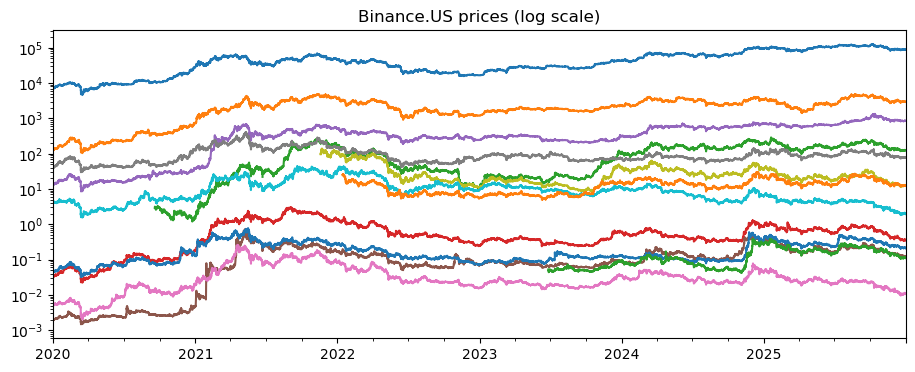

In [7]:
px4.plot(logy=True, figsize=(11, 4), title='Binance.US prices (log scale)', legend=False);

## 2. Momentum: time horizon

Cross-sectional (XS) momentum: at each bar, rank the 13 coins on their average return over the last *h* hours, long the winners and short the losers (demeaned ranks, dollar neutral, Σ|w| = 1), rebalanced every 4h, no costs yet.

Two delays: `shift(1)` holds the position from the next bar; `shift(2)` **skips one bar** (like the classic 12-1 stock momentum, which skips the last month).

In [8]:
hours = [4, 8, 12, 24, 72, 168, 336, 720]

gross_h = {}
for h in hours:
    w = xs_momentum(ret, h)
    for lag in [1, 2]:
        gross_h[(h, lag)] = backtest(w.shift(lag), ret)[0]
gross_h = pd.DataFrame(gross_h)

sharpe(gross_h).unstack().rename(columns={1: 'no skip (shift 1)', 2: 'skip 1 bar (shift 2)'}).round(2)

,no skip (shift 1),skip 1 bar (shift 2)
4,-4.23,0.36
8,-2.77,1.47
12,-1.72,2.11
24,-1.13,0.98
72,0.30,1.19
168,0.84,1.71
336,0.97,1.46
720,0.89,1.34


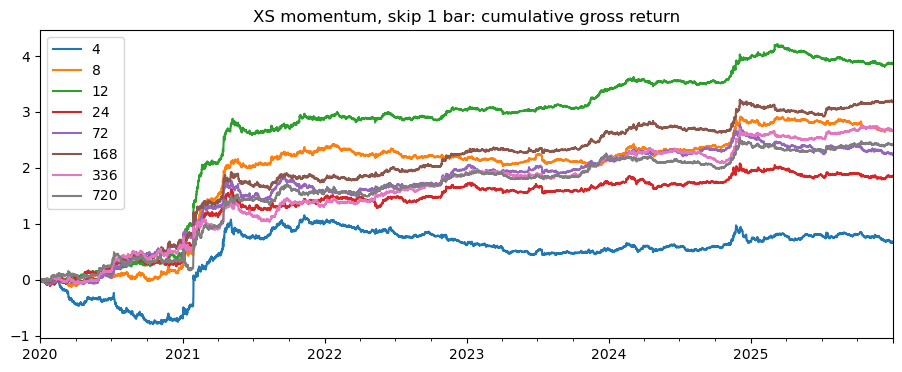

In [9]:
gross_h.xs(2, axis=1, level=1).cumsum().plot(figsize=(11, 4), title='XS momentum, skip 1 bar: cumulative gross return');

**Conclusion.** With no skip, short horizons have strongly **negative** momentum (h=4: −4.2): over a few hours, crypto coins **reverse**. Skipping one bar removes this reversal and every horizon becomes positive (best: h=12 at 2.1, h=168 at 1.7, h=720 at 1.3). From here on, momentum uses `shift(2)`.

## 3. Transaction costs and execution

### 3.1 Costs with 4-hourly rebalancing

In [10]:
gross_c, to_c = {}, {}
for h in hours:
    gross_c[h], to_c[h] = backtest(xs_momentum(ret, h).shift(2), ret)
gross_c, to_c = pd.DataFrame(gross_c), pd.DataFrame(to_c)
cost_table(gross_c, to_c).round(3)

,gross Sharpe,net Sharpe (20bps),net Sharpe (7bps),avg turnover,breakeven (bps)
4,0.363,-19.436,-6.592,1.373,0.365
8,1.470,-12.639,-3.493,0.979,2.071
12,2.109,-9.618,-2.012,0.821,3.580
24,0.976,-7.398,-1.962,0.606,2.325
72,1.186,-3.898,-0.596,0.365,4.659
168,1.715,-1.770,0.494,0.246,9.835
336,1.457,-1.053,0.578,0.175,11.603
720,1.339,-0.346,0.750,0.116,15.896


### 3.2 Rebalance less often

The signal is still computed every 4h, but the position is only updated once a day (00:00 UTC) or once a week (Monday 00:00) and held in between.

In [33]:
rebalance = {'every 4h': np.ones(len(ret), dtype=bool),
             'daily':    ret.index.hour == 0,
             'weekly':   (ret.index.dayofweek == 0) & (ret.index.hour == 0)}

gross_f, to_f = {}, {}
for freq, mask in rebalance.items():
    for h in hours:
        gross_f[(freq, h)], to_f[(freq, h)] = backtest(hold_at(xs_momentum(ret, h), mask).shift(2), ret)
freq_table = cost_table(pd.DataFrame(gross_f), pd.DataFrame(to_f))
display(freq_table['net Sharpe (20bps)'].unstack(0)[list(rebalance)]
        .rename_axis(index='lookback h (hours)', columns='rebalance')
        .style.format('{:.2f}').set_caption('XS momentum: net Sharpe (20 bps) by rebalance frequency'))
display(freq_table['breakeven (bps)'].unstack(0)[list(rebalance)]
        .rename_axis(index='lookback h (hours)', columns='rebalance')
        .style.format('{:.1f}').set_caption('XS momentum: break-even cost (bps) by rebalance frequency'))



rebalance,every 4h,daily,weekly
lookback h (hours),,,
4,-19.44,-1.75,-0.83
8,-12.64,-1.60,-0.64
12,-9.62,-1.77,-0.33
24,-7.40,-2.53,0.07
72,-3.90,-0.28,-0.25
168,-1.77,0.05,0.48
336,-1.05,0.32,0.08
720,-0.35,0.67,0.20


rebalance,every 4h,daily,weekly
lookback h (hours),,,
4,0.4,9.0,-12.6
8,2.1,9.8,-5.8
12,3.6,9.1,6.6
24,2.3,4.6,22.9
72,4.7,17.1,9.0
168,9.8,20.7,39.2
336,11.6,26.7,24.5
720,15.9,40.9,36.0


In [34]:
# robustness: does the daily result depend on the hour of the day we rebalance? (net Sharpe, 20 bps)
rob_hour = {}
for hr in range(0, 24, 4):
    for h in [168, 336, 720]:
        g, t = backtest(hold_at(xs_momentum(ret, h), ret.index.hour == hr).shift(2), ret)
        rob_hour[(hr, h)] = sharpe(g - COST*t)
pd.Series(rob_hour).unstack().rename_axis(index='rebalance hour', columns='h').round(2)

h,168,336,720
rebalance hour,,,
0,0.05,0.32,0.67
4,0.26,0.55,0.80
8,0.13,0.49,0.61
12,-0.07,0.45,0.67
16,-0.18,0.37,0.60
20,-0.30,0.10,0.62


### 3.3 Optimization with a transaction-cost penalty (cvxpy)

Following `PythonCvxOpt.ipynb`, every day at 00:00 we solve

$$\min_w \;(w-w^*)^\top \Sigma\,(w-w^*) \;+\; \lambda \cdot c \cdot \lVert w - w_{prev}\rVert_1 \quad \text{s.t.}\quad \textstyle\sum_i w_i = 0,\;\; \lVert w\rVert_1 \le 1$$

- $w^*$ = momentum weights (the ideal portfolio), $\Sigma$ = Ledoit-Wolf covariance of the past 30 days
- $w_{prev}$ = the position **actually held** (yesterday's solution), $c$ = 20 bps, $\lambda$ = `tc_penalty`
- the optimizer only trades coins whose weight is far enough from the ideal to be worth the cost

$\lambda = 0$ gives back the daily rule of 3.2 (sanity check). h = 720 (the best horizon in 3.2), ~20 seconds per run.

In [35]:
gross_o, to_o = {}, {}
for pen in [0, 0.001, 0.003, 0.01]:
    W = rolling_opt(xs_momentum(ret, 720), ret, tc_penalty=pen)
    gross_o[pen], to_o[pen] = backtest(W.reindex(ret.index).ffill().shift(2), ret)
opt_table = cost_table(pd.DataFrame(gross_o), pd.DataFrame(to_o))
opt_table.index.name = 'tc_penalty'
opt_table.round(3)

,gross Sharpe,net Sharpe (20bps),net Sharpe (7bps),avg turnover,breakeven (bps)
tc_penalty,,,,,
0.000,1.318,0.672,1.092,0.043,40.812
0.001,1.285,0.801,1.115,0.032,53.162
0.003,1.211,0.880,1.095,0.021,73.362
0.010,0.858,0.688,0.799,0.010,100.960


**Conclusion.** - **Costs kill everything when rebalancing every 4h**: the break-even cost is at most ~16 bps (h=720), below the 20 bps of market orders. The signal works; the problem is turnover.
- **Daily rebalancing** cuts turnover by ~3× for slow signals with almost no loss of signal: h=720 goes from −0.35 to **0.67** after 20 bps (break-even 41 bps). Short horizons (≤ 72h) stay negative at every frequency. Weekly rebalancing loses too much signal.
- The daily result for h=720 does not depend on the rebalance hour (0.60–0.80), so it is not luck of timing.
- **cvxpy** with λ = 0.003 halves turnover again (0.043 → 0.021) and raises the net Sharpe to **0.88** (break-even 73 bps). λ = 0 reproduces the daily rule (sanity check); too much penalty (λ = 0.01) trades too little and loses signal.

## 4. A better cross-sectional momentum signal

Two changes to the h = 720 signal:
1. **Multi-horizon**: average the ranks of h = 168, 336, 720 (1 week, 2 weeks, 1 month) instead of picking one horizon.
2. **Volatility-adjusted**: rank on past return ÷ past 30-day volatility, so a coin does not rank high just because it is volatile.

Then the same daily rebalance + cvxpy (λ = 0.003).

In [14]:
W_xs = rolling_opt(xs_momentum_mhva(ret), ret, tc_penalty=0.003)     # kept: this is the final XS strategy
g_new, t_new = backtest(W_xs.reindex(ret.index).ffill().shift(2), ret)

xs_cmp = cost_table(pd.DataFrame({'h=720': gross_o[0.003], 'multi-horizon + vol-adjusted': g_new}),
                    pd.DataFrame({'h=720': to_o[0.003], 'multi-horizon + vol-adjusted': t_new}))
display(xs_cmp.round(3))

net_cmp = pd.DataFrame({'h=720': gross_o[0.003] - COST*to_o[0.003], 'multi-horizon + vol-adjusted': g_new - COST*t_new})
net_cmp.groupby(net_cmp.index.year).apply(sharpe).round(2)       # net Sharpe by year

,gross Sharpe,net Sharpe (20bps),net Sharpe (7bps),avg turnover,breakeven (bps)
h=720,1.211,0.88,1.095,0.021,73.362
multi-horizon + vol-adjusted,1.586,1.03,1.391,0.035,57.189


,h=720,multi-horizon + vol-adjusted
2020,0.73,1.95
2021,1.82,1.23
2022,0.90,1.25
2023,1.43,-0.34
2024,0.40,1.33
2025,-0.73,0.15


**Conclusion.** The new signal raises the gross Sharpe (1.21 → 1.59) and, with the optimizer, the **net Sharpe from 0.88 to 1.03**. Without the optimizer the gain would disappear, because the new signal trades more. Both versions are weak in 2025: a first warning that momentum may be fading (see Section 11).

## 5. Momentum and activity (volume)

Project hypothesis: *heightened activity coupled with new information favors momentum.*

Abnormal volume of each coin, relative to its own past (raw volume cannot be compared across coins):

$$\text{avol}_{i,t} = \frac{\text{average 4h volume over the last } h \text{ hours}}{\text{average 4h volume over the last 90 days}}$$

Signals (h = 168 and 720): plain momentum; momentum **only among the high-avol half** of the coins; **only among the low-avol half**; and **volume-weighted** momentum (momentum rank × (1 + avol percentile), so a coin that moved on high volume gets up to 2× the weight). All on the same sample (dates/coins where avol exists).

In [15]:
vm = {}
for h in [168, 720]:
    avol = vol4.rolling(h//4, min_periods=h//4).mean() / vol4.rolling(540, min_periods=270).mean()
    mom = ret.rolling(h//4, min_periods=1).mean()
    valid = mom.notna() & avol.notna()
    mom, avol = mom.where(valid), avol.where(valid)
    av_pct = avol.rank(axis=1, pct=True)
    high = av_pct > 0.5
    mom_rank = mom.rank(axis=1)
    vm[(h, 'plain')]           = norm(mom_rank)
    vm[(h, 'high avol only')]  = norm(mom.where(high).rank(axis=1))
    vm[(h, 'low avol only')]   = norm(mom.where(~high).rank(axis=1))
    vm[(h, 'volume-weighted')] = norm(mom_rank.sub(mom_rank.mean(axis=1), axis=0) * (1 + av_pct))

daily = ret.index.hour == 0
vol_tab = {}
for (h, name), w in vm.items():
    g4, _ = backtest(w.shift(2), ret)                        # unconstrained, every 4h
    gd, td = backtest(hold_at(w, daily).shift(2), ret)       # daily rebalance, with costs
    vol_tab[(h, name)] = {'gross Sharpe (every 4h)': sharpe(g4), 'net Sharpe 20bps (daily)': sharpe(gd - COST*td),
                          'avg turnover (daily)': td.mean()}
pd.DataFrame(vol_tab).T.round(3)

gross Sharpe (every 4h)  net Sharpe 20bps (daily)  avg turnover (daily)
168 plain                              1.704                     0.028                 0.085
    high avol only                     1.098                    -0.543                 0.104
    low avol only                      0.512                    -0.874                 0.114
    volume-weighted                    1.673                     0.010                 0.086
720 plain                              1.372                     0.681                 0.040
    high avol only                     0.778                    -0.076                 0.049
    low avol only                      0.565                    -0.133                 0.057
    volume-weighted                    1.319                     0.639                 0.041

**Conclusion.** **Weak support for the hypothesis, but no tradable improvement.** Before costs, momentum among high-volume coins is stronger than among low-volume coins (1.10 vs 0.51 for h=168; 0.78 vs 0.57 for h=720), in line with the project's hypothesis. But with only 13 coins, keeping half of them costs more diversification than the volume information adds, and the groups trade more (coins move in and out). Volume-weighting keeps all coins but is still slightly below plain momentum (0.64 vs 0.68 net). Binance.US volume is also a small and noisy slice of global crypto activity.

## 6. Time-series momentum

XS momentum compares coins with each other and is market-neutral. **Time-series (TS) momentum** asks whether the **market** is trending: long all coins (equal weight) if the equal-weight market rose over the last *L* days, short if it fell. It is directional by design.

Single lookbacks (7, 14, 30, 60 days) are noisy, so the main signal is the **average of the four signs** (position between −1 and +1, smaller when the lookbacks disagree). Daily rebalance, `shift(2)`.

In [16]:
m_ = ret.mean(axis=1)
ts_sigs = {f'{L}d': np.sign(m_.rolling(L*6, min_periods=L*6).sum()) for L in [7, 14, 30, 60]}
ts_avg = ts_market(ret)[1]
ts_sigs['average 7-60d'] = ts_avg

gross_t, to_t = {}, {}
for name, s in ts_sigs.items():
    gross_t[name], to_t[name] = backtest(hold_at(equal_weight(ret).mul(s, axis=0), daily).shift(2), ret)
gross_t, to_t = pd.DataFrame(gross_t), pd.DataFrame(to_t)
ts_table = cost_table(gross_t, to_t)
ts_table['annual vol'] = gross_t.std()*np.sqrt(BARS_PER_YEAR)
ts_table['max drawdown'] = (gross_t - COST*to_t).apply(max_drawdown)
ts_table['corr with XS'] = (gross_t - COST*to_t).corrwith(g_new - COST*t_new)
ts_table.round(3)

,gross Sharpe,net Sharpe (20bps),net Sharpe (7bps),avg turnover,breakeven (bps),annual vol,max drawdown,corr with XS
7d,0.676,0.361,0.566,0.057,42.984,0.796,-1.164,0.128
14d,1.288,1.106,1.225,0.033,141.612,0.790,-0.854,0.162
30d,0.803,0.663,0.754,0.025,114.931,0.782,-1.096,0.150
60d,0.937,0.852,0.907,0.015,219.852,0.757,-1.098,0.142
average 7-60d,1.103,0.906,1.034,0.027,112.055,0.603,-0.624,0.182


**Conclusion.** - TS momentum survives costs easily: it rarely changes direction (break-even 43–220 bps).
- Single lookbacks are noisy (net 0.36 to 1.11). Picking the best one (14d) would be overfitting; the **average 7–60d signal** gives net **0.91** with the lowest vol (60%) and drawdown.
- It is very volatile and directional, but its correlation with XS momentum is low (0.18): a good diversifier.

## 7. Reversal

Project ideas: shorter horizons reverse; uninformed (liquidity-driven) trading reverses; *security A − something correlated to it* is more mean-reverting; the "Fire Sale" video.

A key issue for reversal is **data quality**. Binance.US is thin for small coins (stale prices, small orders moving the price), which creates *fake* reversal. To check this, each reversal idea is also run on **Binance global** data for the same 13 coins (much higher volume), over the same period 2020–2024. Binance global data come from Binance's public mirror `data-api.binance.vision` (`api.binance.com` blocks US IPs); see `project.ipynb`, Step 8a.

In [17]:
px_g = pd.read_pickle('data/global_px_1h.pk')       # Binance global, same 13 coins, Jan-2020 -> Oct-2026
vol_g = pd.read_pickle('data/global_vol_1h.pk')
ret_g = px_g.resample('4h').last().pct_change(fill_method=None)

# same period for both sources
r_us, r_gl = ret.loc[:'2024'], ret_g.loc[:'2024']
pd.DataFrame({'median $vol/hour, Binance.US (2024)':     vol.loc['2024'].median().round(0),
              'median $vol/hour, Binance global (2024)': vol_g.loc['2024'].median().round(0),
              'corr of 4h returns US vs global (2024)':  ret.loc['2024'].corrwith(ret_g.loc['2024']).round(3)})

,"median $vol/hour, Binance.US (2024)","median $vol/hour, Binance global (2024)",corr of 4h returns US vs global (2024)
BTCUSDT,66899.0,65169926.0,0.991
ETHUSDT,23378.0,35481866.0,0.993
SOLUSDT,32556.0,20838231.0,0.989
ADAUSDT,4543.0,1787902.0,0.989
BNBUSDT,6969.0,6919202.0,0.982
DOGEUSDT,9114.0,5600845.0,0.991
VETUSDT,1432.0,287718.0,0.972
LTCUSDT,1472.0,1281609.0,0.985
AVAXUSDT,2411.0,2521362.0,0.988
ATOMUSDT,518.0,591266.0,0.962


### 7.1 Short-term cross-sectional reversal

Minus the 4h momentum weights, no skip (`shift(1)`), rebalanced every 4h.

In [18]:
rev_tab = {}
for name, r in [('Binance.US', r_us), ('Binance global', r_gl)]:
    g, t = backtest((-xs_momentum(r, 4)).shift(1), r)
    rev_tab[name] = cost_table(pd.DataFrame({'4h reversal': g}), pd.DataFrame({'4h reversal': t})).iloc[0]
pd.DataFrame(rev_tab).T.round(3)

,gross Sharpe,net Sharpe (20bps),net Sharpe (7bps),avg turnover,breakeven (bps)
Binance.US,3.487,-14.840,-2.942,1.368,3.796
Binance global,1.581,-17.318,-5.047,1.351,1.670


### 7.2 Pairs trading

All 78 pairs. Spread = log(A) − β·log(B) with β from a 30-day rolling regression; z = (spread − 30-day mean) / 30-day std. Open when |z| > 2.5 (short the spread if high, long if low), close when |z| < 0.5. Each pair has gross exposure 1; pairs are equally weighted.

In [19]:
def pairs_trading(r, px1h, entry=2.5, exit=0.5, W=180):
    lp = np.log(px1h.resample('4h').last().loc[r.index])
    G, T = [], []
    for a, b in itertools.combinations(r.columns, 2):
        beta = lp[a].rolling(W).cov(lp[b]) / lp[b].rolling(W).var()
        spread = lp[a] - beta*lp[b]
        z = (spread - spread.rolling(W).mean()) / spread.rolling(W).std()
        pos = pd.Series(np.nan, index=z.index)
        pos[z > entry], pos[z < -entry], pos[z.abs() < exit] = -1, 1, 0
        pos = pos.ffill().fillna(0)
        w = pd.DataFrame({a: pos/(1 + beta.abs()), b: -pos*beta/(1 + beta.abs())}).fillna(0)
        g, t = backtest(w.shift(1), r[[a, b]].fillna(0))
        G.append(g); T.append(t)
    return pd.concat(G, axis=1).mean(axis=1), pd.concat(T, axis=1).mean(axis=1)

pair_tab = {}
for name, r, p in [('Binance.US', r_us, px), ('Binance global', r_gl, px_g)]:
    g, t = pairs_trading(r, p)
    pair_tab[name] = cost_table(pd.DataFrame({'pairs': g}), pd.DataFrame({'pairs': t})).iloc[0]
pd.DataFrame(pair_tab).T.round(3)

,gross Sharpe,net Sharpe (20bps),net Sharpe (7bps),avg turnover,breakeven (bps)
Binance.US,1.477,0.760,1.226,0.006,41.168
Binance global,0.718,-0.007,0.464,0.008,19.804


### 7.3 Fire sale

Sharp market-wide drops in crypto are often driven by **forced liquidations of leveraged positions** and panic, i.e. uninformed selling. Strategy: if the equal-weight market's 24h return is below **−k** standard deviations (90-day vol), **buy the whole market** and hold for 24 hours; otherwise stay flat. Main setting k = 2. No skip (`shift(1)`).

In [20]:
fs_tab = {}
for name, r in [('Binance.US', ret), ('Binance global 2020-24', r_gl)]:
    for k in [1.5, 2.0, 2.5]:
        w, s = fire_sale(r, k)
        g, t = backtest(w.shift(1), r)
        row = cost_table(pd.DataFrame({'x': g}), pd.DataFrame({'x': t})).iloc[0]
        row['time in market'] = (s > 0).mean()
        row['events'] = (s.diff() > 0).sum()
        fs_tab[(name, k)] = row
pd.DataFrame(fs_tab).T.round(3)

gross Sharpe  net Sharpe (20bps)  net Sharpe (7bps)  avg turnover  breakeven (bps)  time in market  events
Binance.US             1.5         1.327               0.997              1.212         0.033           80.225           0.145   218.0
                       2.0         0.983               0.767              0.908         0.019           90.621           0.078   121.0
                       2.5         0.930               0.785              0.879         0.010          127.961           0.043    68.0
Binance global 2020-24 1.5         1.463               1.161              1.357         0.033           96.649           0.144   179.0
                       2.0         1.049               0.855              0.981         0.018          107.541           0.078    99.0
                       2.5         0.882               0.754              0.837         0.010          137.265           0.043    57.0

In [21]:
# real reversal or just "crypto went up"? market return in the 24h after a crash vs on average
w_fs, s_fs = fire_sale(ret, 2.0)
in_mkt = s_fs.shift(1) > 0
print(f'average 4h market return, all bars:        {mkt.mean()*1e4:5.1f} bps')
print(f'average 4h market return, 24h after crash: {mkt[in_mkt].mean()*1e4:5.1f} bps')

# robustness on Binance.US: threshold x holding period x delay (net Sharpe, 20 bps)
rob = {}
for k in [1.5, 2.0, 2.5]:
    for hold in [3, 6, 12]:
        for lag in [1, 2]:
            g, t = backtest(fire_sale(ret, k, hold)[0].shift(lag), ret)
            rob[(k, hold*4, lag)] = sharpe(g - COST*t)
rob = pd.Series(rob)
rob.index.names = ['k', 'hold (hours)', 'lag']
display(rob.unstack(['hold (hours)', 'lag']).round(2))

g, t = backtest(w_fs.shift(1), ret)
(g - COST*t).groupby(ret.index.year).apply(sharpe).round(2).rename('net Sharpe by year (k=2)')

average 4h market return, all bars:          4.1 bps
average 4h market return, 24h after crash:  22.1 bps


hold (hours)    12          24          48      
lag              1     2     1     2     1     2
k                                               
1.5           0.66  0.50  1.00  0.27  0.60  0.33
2.0           0.65  0.68  0.77  0.45  0.55  0.25
2.5           0.88  0.75  0.79  0.77  0.37  0.34

2020   -0.66
2021    1.61
2022    0.14
2023    2.09
2024    1.32
2025    1.47
Name: net Sharpe by year (k=2), dtype: float64

**Conclusion.** - **Short-term reversal is mostly a Binance.US artifact.** The 4h reversal has a gross Sharpe of 3.5 on Binance.US but 1.6 on Binance global, and a break-even cost of 2–4 bps: not tradable.
- **Pairs trading looks profitable on Binance.US (0.76 net) but is ~0 on Binance global.** Prices on the two venues are 96–99% correlated, but pairs trading earns exactly the small part where they differ: Binance.US noise in small coins is mean-reverting by nature, and it dominates the spread once the common market move is removed.
- **Fire sale is real and robust.** Net Sharpe 0.77 (k=2) on Binance.US and 0.86 on Binance global; positive for every threshold, holding period and delay tested. The market return in the 24h after a crash is 22 bps per 4h vs 4 bps on average, so it is reversal, not just "crypto went up". It trades rarely (~120 events, in the market 8% of the time). **Main risk:** a crash that keeps going (2020, COVID: −0.66).

## 8. Betting against beta (BAB)

A classic stock factor (Frazzini & Pedersen, 2014): investors who cannot or will not use leverage buy **high-beta** assets to get high returns, which makes them expensive and lowers their future returns. In crypto, retail investors chase volatile altcoins.

Each month: estimate each coin's beta to the equal-weight market (90 days); **long the low-beta half, short the high-beta half**, each leg scaled by 1/(its average beta) so the two legs have similar market exposure. Monthly rebalance, so costs are tiny.

In [22]:
monthly = (ret.index.day == 1) & (ret.index.hour == 0)
bab_tab = {}
for name, r in [('Binance.US', ret), ('Binance global 2020-24', r_gl)]:
    held = hold_at(betting_against_beta(r), (r.index.day == 1) & (r.index.hour == 0)).shift(1)
    g, t = backtest(held, r)
    n = g - COST*t
    m = r.mean(axis=1)
    b = n.cov(m)/m.var()
    bab_tab[name] = {'net Sharpe (20bps)': sharpe(n), 'breakeven (bps)': g.mean()/t.mean()*1e4,
                     'avg net exposure': held.sum(axis=1).mean(), 'beta': b,
                     'Sharpe of (net - beta x market)': sharpe(n - b*m)}
display(pd.DataFrame(bab_tab).T.round(3))

held_bab = hold_at(betting_against_beta(ret), monthly).shift(1)
g, t = backtest(held_bab, ret)
(g - COST*t).groupby(ret.index.year).apply(sharpe).round(2).rename('BAB net Sharpe by year (Binance.US)')

,net Sharpe (20bps),breakeven (bps),avg net exposure,beta,Sharpe of (net - beta x market)
Binance.US,0.858,635.911,0.180,0.056,0.636
Binance global 2020-24,0.857,597.579,0.175,0.056,0.571


2020    1.81
2021    0.48
2022    0.68
2023    0.07
2024    1.37
2025    1.19
Name: BAB net Sharpe by year (Binance.US), dtype: float64

**Conclusion.** BAB works on both data sources (net 0.86) with almost no market exposure (beta 0.06); after removing the market it keeps a Sharpe of ~0.6. Costs are negligible (break-even ~600 bps). It is uneven across years (strong in 2020, 2024, 2025; weak in 2021, 2023).

## 9. Weighting: combining the strategies

The four strategies, each net of 20 bps, exactly as above:

| | strategy | rebalance |
|---|---|---|
| **XS** | multi-horizon + vol-adjusted momentum, cvxpy (λ = 0.003) | daily |
| **TS** | market time-series momentum, average 7–60d | daily |
| **FS** | fire sale, k = 2, hold 24h | event-driven |
| **BAB** | betting against beta | monthly |

`final_strategies(r)` rebuilds all four from any 4h return panel, so the **same code** is used for the out-of-sample test in Section 11.

Combination methods (capital share of each strategy):
- **equal** (1/N)
- **risk parity**: share ∝ 1/vol over the past year (lagged one bar). Using one year rather than 90 days because FS is flat most of the time.
- **rolling max Sharpe**: $w \propto \Sigma^{-1}\mu$ on all past data (≥ 1 year), negative weights set to 0
- **full-sample max Sharpe**: same formula on the evaluation period itself. It **uses future data** and is only an upper bound.

Evaluation starts one year after the first full signal (Mar-2021), so that every method has enough history.

In [23]:
def final_strategies(r, W_xs=None):
    daily = r.index.hour == 0
    monthly = (r.index.day == 1) & daily
    if W_xs is None:                                        # ~20 seconds
        W_xs = rolling_opt(xs_momentum_mhva(r), r, tc_penalty=0.003)
    ts_w, ts_sig = ts_market(r)
    held = {'XS':  W_xs.reindex(r.index).ffill().shift(2),
            'TS':  hold_at(ts_w, daily).shift(2),
            'FS':  fire_sale(r, 2.0)[0].shift(1),
            'BAB': hold_at(betting_against_beta(r), monthly).shift(1)}
    R = pd.DataFrame({k: (lambda g, t: g - COST*t)(*backtest(h, r)) for k, h in held.items()})
    start = ts_sig.first_valid_index() + pd.Timedelta('1D')   # TS needs 60 days of history
    return R.loc[start:]

def risk_parity(R, cols, WIN=365*6):
    inv_vol = 1 / R[cols].rolling(WIN, min_periods=WIN//2).std()
    return inv_vol.div(inv_vol.sum(axis=1), axis=0).shift(1)

def rolling_max_sharpe(R, cols, min_hist=365*6):
    a, rp = {}, risk_parity(R, cols)
    for t in R.index[(R.index.hour == 0)][::7]:                 # update weekly
        past = R.loc[:t, cols]
        if len(past) < min_hist:
            continue
        w = np.clip(np.linalg.solve(past.cov().values, past.mean().values), 0, None)
        a[t] = w/w.sum() if w.sum() > 0 else rp.loc[t].values
    return pd.DataFrame(a, index=cols).T.reindex(R.index).ffill().shift(1)

R_us = final_strategies(ret, W_xs)
eval_start = R_us.index[0] + pd.Timedelta('365D')
R_us.loc[eval_start:].corr().round(2)

,XS,TS,FS,BAB
XS,1.00,0.19,0.02,-0.11
TS,0.19,1.00,-0.21,0.01
FS,0.02,-0.21,1.00,0.01
BAB,-0.11,0.01,0.01,1.00


In [24]:
def combinations(R, eval_start):
    E = R.loc[eval_start:]
    out = {c: R[c] for c in ['XS', 'TS', 'FS', 'BAB']}
    for label, cols in [('3 strategies', ['XS', 'TS', 'FS']), ('4 strategies', ['XS', 'TS', 'FS', 'BAB'])]:
        out[f'{label}: equal']               = R[cols].mean(axis=1)
        out[f'{label}: risk parity']         = (risk_parity(R, cols)*R[cols]).sum(axis=1)
        out[f'{label}: rolling max Sharpe']  = (rolling_max_sharpe(R, cols)*R[cols]).sum(axis=1)
        w = np.clip(np.linalg.solve(E[cols].cov().values, E[cols].mean().values), 0, None)
        out[f'{label}: full-sample max Sharpe *'] = R[cols] @ (w/w.sum())
    return pd.DataFrame(out).loc[eval_start:]

combos_us = combinations(R_us, eval_start)
pd.DataFrame({c: perf(combos_us[c], mkt) for c in combos_us}).T.round(3)

,Sharpe,annual return,annual vol,max drawdown,beta
XS,0.812,0.196,0.242,-0.305,0.021
TS,0.510,0.295,0.578,-0.624,-0.012
FS,1.042,0.363,0.349,-0.357,0.204
BAB,0.259,0.045,0.174,-0.456,0.027
3 strategies: equal,1.223,0.285,0.233,-0.197,0.071
3 strategies: risk parity,1.353,0.271,0.201,-0.176,0.076
3 strategies: rolling max Sharpe,1.178,0.264,0.224,-0.212,0.066
3 strategies: full-sample max Sharpe *,1.436,0.288,0.201,-0.153,0.101
4 strategies: equal,1.256,0.225,0.179,-0.156,0.060
4 strategies: risk parity,1.429,0.204,0.143,-0.131,0.061


**Conclusion.** - The four strategies are almost uncorrelated (largest correlation: XS–TS 0.19; TS–FS is −0.21: after a crash TS is often short while FS is long).
- **Risk parity is the best realistic method**: 4 strategies → **Sharpe 1.43**, vol 14%, max drawdown −13%. It is close to the full-sample max Sharpe (1.47), which uses future data.
- **Rolling max Sharpe is the worst** (1.06): it needs estimated mean returns, which are very noisy over a few years.
- BAB has a low Sharpe on this period (0.26) but still improves the combination (1.35 → 1.43), lowers vol (20% → 14%) and drawdown, and makes the yearly results more even, because it is uncorrelated (and slightly negatively correlated with XS).

## 10. Performance evaluation (in-sample, Binance.US)

Final strategy: **4 strategies, risk parity**. Alpha and beta from a regression of its 4h returns on the equal-weight market and on BTC.

In [25]:
final_us = combos_us['4 strategies: risk parity']

def alpha_beta(x, f):
    f = f.loc[x.index]
    beta = x.cov(f)/f.var()
    resid = x - beta*f
    alpha = resid.mean()
    t_alpha = alpha / (resid.std()/np.sqrt(len(resid)))
    return pd.Series({'beta': beta, 'annual alpha': alpha*BARS_PER_YEAR, 't-stat (alpha)': t_alpha})

display(perf(final_us, mkt).round(3).to_frame('final strategy'))
pd.DataFrame({'vs equal-weight market': alpha_beta(final_us, mkt),
              'vs BTC': alpha_beta(final_us, ret['BTCUSDT'])}).round(3)

,final strategy
Sharpe,1.429
annual return,0.204
annual vol,0.143
max drawdown,-0.131
beta,0.061


,vs equal-weight market,vs BTC
beta,0.061,0.075
annual alpha,0.177,0.183
t-stat (alpha),2.894,2.949


In [26]:
yearly = combos_us[['XS', 'TS', 'FS', 'BAB', '3 strategies: risk parity', '4 strategies: risk parity']]
yearly.groupby(yearly.index.year).apply(sharpe).round(2)

,XS,TS,FS,BAB,3 strategies: risk parity,4 strategies: risk parity
2021,1.25,0.82,1.34,-1.41,1.77,1.26
2022,1.25,0.17,0.14,0.68,1.01,1.20
2023,-0.34,1.27,2.09,0.07,1.15,1.30
2024,1.33,0.96,1.32,1.37,1.96,2.24
2025,0.15,-0.32,1.47,1.19,0.72,1.29


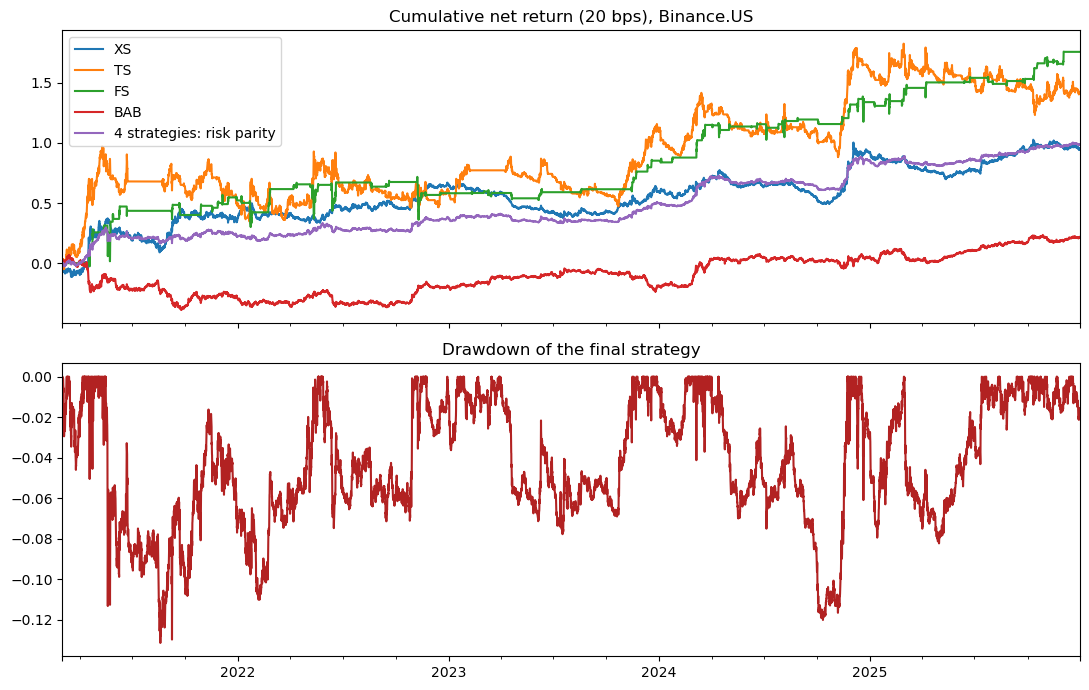

In [27]:
fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
combos_us[['XS', 'TS', 'FS', 'BAB', '4 strategies: risk parity']].cumsum().plot(ax=ax[0], title='Cumulative net return (20 bps), Binance.US')
cum = final_us.cumsum()
(cum - cum.cummax()).plot(ax=ax[1], color='firebrick', title='Drawdown of the final strategy')
plt.tight_layout()

**Conclusion.** - Final strategy (Binance.US, Mar-2021 → Dec-2025): **Sharpe 1.43, annual return 20%, vol 14%, max drawdown −13%**.
- **Market-neutral in practice**: beta 0.06 to the equal-weight market and 0.08 to BTC. **Alpha ≈ 18% per year, t-stat ≈ 2.9**.
- Positive every year (1.20–2.24).
- Caveats: the parameters were chosen on this same data (in-sample); 2020 is excluded from the evaluation (FS's only losing year); costs are a fixed estimate (20 bps); weights drift between rebalances is ignored.

## 11. Out-of-sample test on Binance global data

**Why Binance global:** Binance.US volume collapsed in 2026 (e.g. VET ≈ \$33/hour, ATOM ≈ \$17/hour), so its prices would be stale. Binance global trades the same coins with ~1000× the volume, and 4h returns of the two venues are highly correlated (Section 7).

**Rules:** same 13 coins, same signals and parameters, nothing re-tuned. Out-of-sample = **Jan-2025 → Oct-2026**. 2025 was partly seen during development (the yearly tables above include it), so **2026 is the truly unseen period**.

In [28]:
pd.DataFrame({'median $vol/hour 2026, Binance.US': pd.read_pickle('data/vol_liquid_1h_full.pk').loc['2026'].median().round(0),
              'median $vol/hour 2026, Binance global': vol_g.loc['2026'].median().round(0)})

,"median $vol/hour 2026, Binance.US","median $vol/hour 2026, Binance global"
BTCUSDT,42820.0,39117364.0
ETHUSDT,24025.0,20419904.0
SOLUSDT,7995.0,7362647.0
ADAUSDT,820.0,977479.0
BNBUSDT,1349.0,2704816.0
DOGEUSDT,2082.0,2044896.0
VETUSDT,33.0,47300.0
LTCUSDT,410.0,570388.0
AVAXUSDT,242.0,650924.0
ATOMUSDT,17.0,83527.0


In [29]:
R_g = final_strategies(ret_g)
mkt_g = ret_g.mean(axis=1)
combos_g = combinations(R_g, eval_start)
cols = ['4 strategies: risk parity', '3 strategies: risk parity', 'XS', 'TS', 'FS', 'BAB']

periods = {'in-sample (Mar-2021 → 2024)': (eval_start, '2024'),
           '2025': ('2025', '2025'), '2026 (Jan–Oct)': ('2026', '2026'),
           'out-of-sample 2025–2026': ('2025', '2026')}
oos = pd.concat({p: pd.DataFrame({c: perf(combos_g.loc[a:b, c], mkt_g) for c in cols}).T for p, (a, b) in periods.items()})
oos.round(3)

Sharpe  annual return  annual vol  max drawdown   beta
in-sample (Mar-2021 → 2024) 4 strategies: risk parity   1.733          0.263       0.152        -0.124  0.076
                            3 strategies: risk parity   1.765          0.376       0.213        -0.182  0.101
                            XS                          1.154          0.284       0.246        -0.299  0.031
                            TS                          0.822          0.507       0.617        -0.567  0.064
                            FS                          1.106          0.413       0.374        -0.351  0.218
                            BAB                         0.257          0.045       0.175        -0.356  0.027
2025                        4 strategies: risk parity   1.965          0.193       0.098        -0.076  0.007
                            3 strategies: risk parity   1.349          0.200       0.148        -0.089 -0.028
                            XS                          0.573          0.097       0.170        -0.208 -0.041
                            TS                         -0.269         -0.155       0.577        -0.613 -0.243
                            FS                          2.200          0.565       0.257        -0.102  0.126
                            BAB                         1.432          0.182       0.127        -0.118  0.055
2026 (Jan–Oct)              4 strategies: risk parity  -0.050         -0.004       0.080        -0.060  0.027
                            3 strategies: risk parity  -0.838         -0.086       0.103        -0.137  0.036
                            XS                         -1.083         -0.146       0.135        -0.181  0.002
                            TS                         -0.074         -0.029       0.398        -0.518 -0.072
                            FS                         -0.102         -0.019       0.186        -0.186  0.131
                            BAB                         1.032          0.111       0.107        -0.081  0.012
out-of-sample 2025–2026     4 strategies: risk parity   1.167          0.106       0.091        -0.076  0.012
                            3 strategies: risk parity   0.563          0.073       0.130        -0.137 -0.009
                            XS                         -0.068         -0.011       0.156        -0.208 -0.029
                            TS                         -0.197         -0.099       0.506        -0.646 -0.194
                            FS                          1.341          0.306       0.228        -0.186  0.127
                            BAB                         1.267          0.150       0.119        -0.118  0.043

,4 strategies: risk parity,3 strategies: risk parity
2021,2.22,2.57
2022,0.78,0.97
2023,1.14,1.19
2024,2.53,2.08
2025,1.96,1.35
2026,-0.05,-0.84


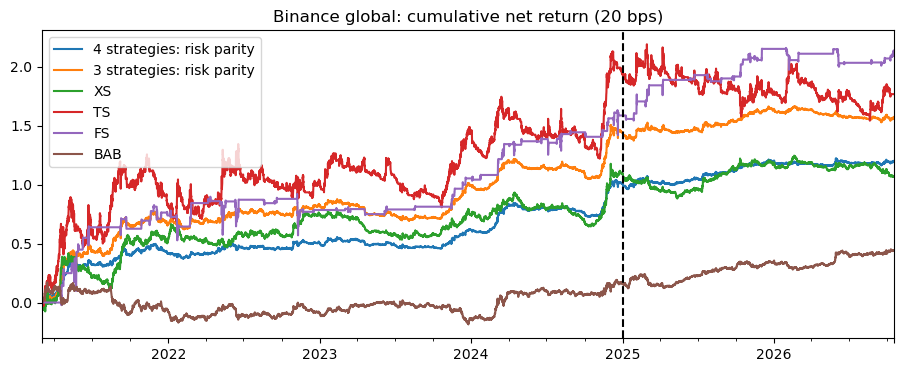

In [30]:
x = combos_g[['4 strategies: risk parity', '3 strategies: risk parity']]
display(x.groupby(x.index.year).apply(sharpe).round(2))
ax = combos_g[cols].cumsum().plot(figsize=(11, 4), title='Binance global: cumulative net return (20 bps)')
ax.axvline(pd.Timestamp('2025-01-01'), color='k', ls='--');

### 11.1 Why did momentum fail in 2026?

In [31]:
pxd = px_g.resample('1D').last()
rd = pxd.pct_change(fill_method=None)
r30 = pxd.pct_change(30)
ic = r30.rank(axis=1).corrwith(r30.shift(-30).rank(axis=1), axis=1)   # does last month's rank predict next month's?
diag = {}
for y in range(2020, 2027):
    s = str(y)
    c = rd.loc[s].corr().values
    diag[y] = {'market return': (1 + rd.loc[s].mean(axis=1)).prod() - 1,
               'cross-sectional dispersion (30d)': r30.loc[s].std(axis=1).mean(),
               'average pairwise correlation': c[np.triu_indices_from(c, 1)].mean(),
               'rank IC (past 30d -> next 30d)': ic.loc[s].mean(),
               '30d market trend changes': (np.sign(rd.mean(axis=1).rolling(30).sum()).loc[s].diff().abs() > 0).sum()/2}
display(pd.DataFrame(diag).T.round(3))

y26 = combos_g.loc['2026']
monthly26 = pd.concat({'market': mkt_g.loc['2026'], **{c: y26[c] for c in ['XS', 'TS', 'FS', 'BAB']}}, axis=1)
(monthly26.groupby(monthly26.index.month).sum()*100).round(1).rename_axis('2026 month (return %)')

,market return,cross-sectional dispersion (30d),average pairwise correlation,rank IC (past 30d -> next 30d),30d market trend changes
2020,2.694,0.271,0.578,0.104,10.0
2021,12.206,0.547,0.494,-0.020,11.5
2022,-0.739,0.129,0.763,-0.093,18.0
2023,1.355,0.149,0.579,0.070,9.5
2024,0.951,0.226,0.565,-0.033,17.5
2025,-0.419,0.113,0.741,-0.013,11.0
2026,-0.156,0.091,0.678,-0.101,23.0


,market,XS,TS,FS,BAB
2026 month (return %),,,,,
1,-13.0,-4.5,7.7,-1.6,-3.1
2,-9.8,5.5,1.7,-3.3,-4.5
3,-1.6,-1.0,-4.2,0.8,3.1
4,4.8,-4.2,-12.1,0.0,1.4
5,3.9,2.4,-2.5,3.8,9.4
6,-26.2,-2.0,9.2,-11.5,-2.0
7,3.6,1.9,-16.0,0.0,0.1
8,20.9,0.7,0.9,0.3,0.7
9,23.6,-7.4,17.8,3.4,1.5


**Conclusion.** - **On Binance global the strategy holds in-sample** (1.73), so it is not an artifact of Binance.US prices (unlike pairs trading).
- **Out-of-sample 2025–2026: Sharpe 1.17**, vol 9%, max drawdown −8%. The 4-strategy combination is far more robust than the 3-strategy one (0.56).
- **2026 (the truly unseen period) is flat** (−0.05). XS momentum lost (−1.08); TS and fire sale were about flat; **BAB was the only winner (1.03)** and kept the combination from losing.
- **Why momentum failed in 2026:**
  1. coins moved together: cross-sectional dispersion was the lowest of all years (0.09), so there was little spread to earn;
  2. last month's winners became next month's losers: rank IC −0.10, the lowest of all years (similar to the 2022 bear market);
  3. a sharp rebound inside a bear market (Aug–Sep +21%, +24% after −26% in June) hit the short side of XS (Sep: −7.4%), the classic **momentum crash** (Daniel & Moskowitz, 2016);
  4. the market trend changed direction 23 times, the most of any year, which whipsawed TS (Apr −12%, Jul −16%).
- 9.5 months is short: the standard error of a Sharpe ratio over that period is ≈ 1.1, so 2026 alone is not statistically different from the in-sample result. But weak momentum in both 2025 and 2026 is a real warning.

## 12. Conclusions and limitations

**What worked**
1. **Cross-sectional momentum** over 1 week – 1 month, skipping the most recent bar. It only survives costs with **daily rebalancing plus a cost-aware optimizer** (cvxpy); a multi-horizon, volatility-adjusted signal improves it further.
2. **Time-series momentum** on the market, averaged over several lookbacks: low turnover, low correlation with XS.
3. **Fire sale**: buying the market after a liquidation-driven crash. The only reversal that is robust on clean data.
4. **Betting against beta**: weak on its own recently, but an excellent diversifier.
5. **Risk-parity weighting** of these nearly uncorrelated strategies: Sharpe 1.43 in-sample, 1.17 out-of-sample, near-zero beta.

**What did not work (and why)**
- Short-horizon reversal and pairs trading: their profits on Binance.US come mostly from price noise in illiquid coins; they vanish on Binance global.
- Volume conditioning: the direction matches the hypotheses, but with 13 coins the information does not compensate for lost diversification.
- Rolling max-Sharpe weighting: too sensitive to noisy mean estimates.

**Limitations**
- Small universe (13 coins), short history (6 years), many specifications tried on the same data → in-sample Sharpes are optimistic.
- Costs are a single estimate (20 bps); capacity on Binance.US is very small; shorting requires perpetual futures or margin, with funding costs not modeled.
- The coin universe was chosen with full-sample volume (mild look-ahead); weight drift between rebalances is ignored.
- Momentum weakened in 2025–2026. A natural extension is momentum-crash protection (scaling XS down in high-volatility bear markets), which would need to be validated on new data.